# Episode 003 · Points, directions, and rotation pivots

**Question:** translation moves a point, so why does it not move a direction? How can we rotate a robot around a chosen point?

Episode 002 taught us to express one fixed landmark in different frames. We now distinguish a **location** from a **direction**, using the same rigid matrices. Later in this notebook we use those matrices to move geometry inside a single world frame. That operation changes the object's physical location, while the world axes stay fixed.

This notebook runs independently of the playground. Use Python 3.13 and follow the [episode setup guide](README.md). Run cells in order. Each experiment has a saved reference figure; its sliders and selectors need a live Jupyter kernel.

We use world x/y coordinates in meters and positive counterclockwise angles. Slider angles are in degrees. A displacement has units of meters; a unit forward direction has dimensionless components and length one. The third homogeneous entry is a **weight**, not height or a physical z coordinate.

Work through each experiment in order: predict, change one control, and explain the picture before combining changes.

In [1]:
# Voiceover: We will compare locations with directions, then choose a point around which to turn.
# The drawing helpers present our results; the calculations remain here in the notebook.
import numpy as np
import ipywidgets as widgets
from IPython.display import display
from plotting import (show_anchored_arrow, show_weighted_transform,
                      show_endpoint_check, show_pivot_steps, show_robot_rotation)
np.set_printoptions(precision=3, suppress=True)

## 1. Move an arrow without turning it

**What we know:** two points, A at $(1,1)$ and B at $(3,2)$ meters, define an arrow from A to B. A point answers "where?" The offset between these points answers "how far and in which direction?"

**What we want:** describe the arrow independently of where we draw it.

1. Subtract A from B because we need the offset, rather than either endpoint's location.
   $$
   d=B-A=\begin{bmatrix}3-1\\2-1\end{bmatrix}
     =\begin{bmatrix}2\\1\end{bmatrix}\text{ m}.
   $$
2. Choose a new anchor A and put B at A plus the same offset. This moves both endpoints without turning or stretching the arrow.
3. Subtract the new endpoints to check that the offset stayed the same.

The solid arrow is drawn at the editable anchor. The dashed arrow draws the same vector at the world origin for comparison. A direction has no particular location of its own; an anchor is a drawing choice.

**Predict:** move the anchor one meter right. Which numbers change: A, B, or the components of d? Change only anchor x first, then anchor y. The vector's length stays $\sqrt{5}$ meters. We do not normalize it.

In [2]:
# We know the two endpoints. Their difference tells us the arrow's offset.
# Move its anchor and watch both points move while the offset remains unchanged.
def anchored_arrow_experiment(anchor_x=1.0, anchor_y=1.0):
    a = np.array([anchor_x, anchor_y], dtype=float)
    original_direction = np.array([2.0, 1.0])
    b = a + original_direction
    direction = b - a
    np.testing.assert_allclose(direction, original_direction)
    show_anchored_arrow(a, b, direction)
    return {'a': a, 'b': b, 'direction': direction}

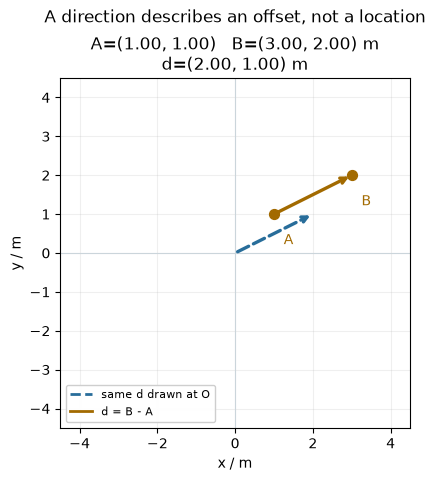

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Anchor x', max=3.0, min=-3.…

In [3]:
# Start with one change to the anchor, then try the other control.
# Compare the two arrow positions before reading their identical vector components.
anchored_arrow_experiment()
anchor_lab = widgets.interactive(
    anchored_arrow_experiment,
    anchor_x=widgets.FloatSlider(value=1, min=-3, max=3, step=0.25,
                                description='Anchor x', continuous_update=False),
    anchor_y=widgets.FloatSlider(value=1, min=-3, max=3, step=0.25,
                                description='Anchor y', continuous_update=False),
)
display(anchor_lab)

## 2. Use one matrix for a point and a direction

**Question:** how can the same robot-to-world matrix tell us both **where a point is** and **which way the robot points**?

In the previous experiment, moving an arrow's endpoints changed their positions but left their difference unchanged. We now need our matrix calculation to respect that distinction.

**What we know:** a point $p_{\text{robot}}=(2,1)$ meters and the robot's unit forward direction $d_{\text{robot}}=(1,0)$, both expressed along robot axes. We also know the robot's pose in the world: $R$ describes its orientation, and $t=(t_x,t_y)$ meters is its origin's world position.

**What we want:** the point's world position $p_{\text{world}}$ and the forward direction's world components $d_{\text{world}}$. We keep the robot-frame inputs fixed and change the robot pose. This means our input point moves with the robot.

### Step 1: Decide what each result needs

If the robot moves one meter right without turning, the point must move one meter right in the world. Its world position needs the robot's translation.

The robot still points the same way, however. A direction describes an orientation and magnitude; it does not store a starting location. Its world components need the rotation, but no translation.

Our goal is to express both rules using the **same** matrix. When we later transform a robot's center and forward axis, we will need this exact distinction.

### Step 2: See why we need a third entry

Episode 002's matrix combines rotation and translation:

$$
T_{\text{world}\leftarrow\text{robot}}=
\begin{bmatrix}
\cos\theta&-\sin\theta&t_x\\
\sin\theta&\cos\theta&t_y\\
0&0&1
\end{bmatrix}.
$$

It has three columns, so multiplying it requires a vector with three entries. Our physical input has only two components. We append a third entry, called the **homogeneous coordinate** $w$, to use this matrix representation.

The name "weight" comes from what that entry does in the multiplication. Expand it before choosing its value:

$$
T
\begin{bmatrix}x\\y\\w\end{bmatrix}
=
\begin{bmatrix}
x\cos\theta-y\sin\theta+t_xw\\
x\sin\theta+y\cos\theta+t_yw\\
w
\end{bmatrix}.
$$

The rotation acts on $x$ and $y$. The translation is multiplied by $w$. This is the reason for the extra entry: it lets the same multiplication include or exclude translation.

Here $w$ describes how we represent the input. It is not a height or another physical axis, and it is not a slider-controlled measurement.

### Step 3: Choose the representation that gives the required behavior

For a **point**, we want to add the translation once. We represent it with $w=1$:

$$
T
\begin{bmatrix}p_x\\p_y\\1\end{bmatrix}
=
\begin{bmatrix}Rp+t\\1\end{bmatrix}.
$$

For a **direction**, we want the translation to contribute nothing. We represent it with $w=0$:

$$
T
\begin{bmatrix}d_x\\d_y\\0\end{bmatrix}
=
\begin{bmatrix}Rd\\0\end{bmatrix}.
$$

We choose these entries from the meaning of the input. We do not choose arbitrary weights to tune the movement.

### Step 4: Apply the matrix and compare the visible results

Start with $t=(1,-1)$ meters and no rotation. The matrix becomes a pure translation:

$$
\begin{bmatrix}1&0&1\\0&1&-1\\0&0&1\end{bmatrix}
\begin{bmatrix}2\\1\\1\end{bmatrix}
=
\begin{bmatrix}3\\0\\1\end{bmatrix},
\qquad
\begin{bmatrix}1&0&1\\0&1&-1\\0&0&1\end{bmatrix}
\begin{bmatrix}1\\0\\0\end{bmatrix}
=
\begin{bmatrix}1\\0\\0\end{bmatrix}.
$$

The point's world position is $(3,0)$ meters. The forward direction is still $(1,0)$.

In the code below, `transform_point` appends `1.0` and `transform_direction` appends `0.0`. Both multiply by the same matrix and read its first two output components.

The **left panel** shows the fixed robot-frame inputs in blue. The **right panel** shows the computed world-frame results in gold. Compare the dot's coordinates and the arrow's orientation. The arrow is drawn at each panel's origin to compare its components; that drawing anchor is not a position stored in the direction.

### Step 5: Change one thing at a time

1. Keep **Turn / deg** at zero. Change only **Shift x / m**, then only **Shift y / m**. The gold point moves; the gold direction stays $(1,0)$.
2. Set both shifts to zero. Set the turn to **90 degrees**. The point becomes $(-1,2)$ meters, and the forward direction becomes $(0,1)$. Rotation affects both; the direction's length remains one.
3. Keep the 90-degree turn and change either shift again. The point's position changes, while the direction stays $(0,1)$.

**Takeaway:** we are checking that one matrix performs two appropriate operations. Points receive rotation and translation; directions receive rotation only. The extra coordinate $w$encodes that difference. Next, we will verify the direction result by transforming two endpoints and subtracting them.


In [13]:
# The last column contributes to a point because its weight is one.
# A direction uses zero, so the same multiplication rotates it without adding translation.
def rigid_transform(tx=0.0, ty=0.0, heading_degrees=0.0):
    angle = np.deg2rad(heading_degrees)
    cosine, sine = np.cos(angle), np.sin(angle)
    return np.array([[cosine, -sine, tx], [sine, cosine, ty], [0, 0, 1]], dtype=float)

def transform_point(target_from_source, point_in_source):
    homogeneous_point = np.append(np.asarray(point_in_source, dtype=float), 1.0)
    return (target_from_source @ homogeneous_point)[:2]

def transform_direction(target_from_source, direction_in_source):
    homogeneous_direction = np.append(np.asarray(direction_in_source, dtype=float), 0.0)
    return (target_from_source @ homogeneous_direction)[:2]

def weighted_transform_experiment(tx=1.0, ty=-1.0, heading_degrees=0.0):
    transform = rigid_transform(tx, ty, heading_degrees)
    point, direction = np.array([2.0, 1.0]), np.array([1.0, 0.0])
    moved_point = transform_point(transform, point)
    moved_direction = transform_direction(transform, direction)
    np.testing.assert_allclose(np.linalg.norm(moved_direction), 1.0, atol=1e-12)
    show_weighted_transform(point, direction, moved_point, moved_direction)
    return {'point': moved_point, 'direction': moved_direction}

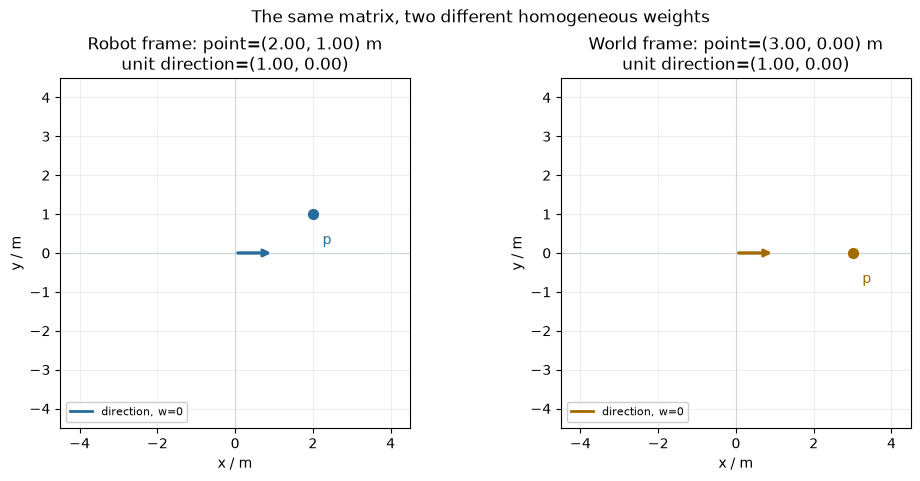

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Shift x / m', max=3.0, min=…

In [14]:
# The dot moves when we change translation, but the forward arrow does not.
# Now turn the transform and observe that both the point and the direction respond to rotation.
weighted_transform_experiment()
weights_lab = widgets.interactive(
    weighted_transform_experiment,
    tx=widgets.FloatSlider(value=1, min=-3, max=3, step=0.25,
                           description='Shift x / m', continuous_update=False),
    ty=widgets.FloatSlider(value=-1, min=-3, max=3, step=0.25,
                           description='Shift y / m', continuous_update=False),
    heading_degrees=widgets.FloatSlider(value=0, min=-180, max=180, step=15,
                                        description='Turn / deg', continuous_update=False),
)
display(weights_lab)

## 3. Check a direction using transformed endpoints

**What we know:** in robot coordinates, A is $(1,1)$ and B is $(3,2)$ meters, so $d=B-A=(2,1)$ meters. The robot-to-world transform rotates by 90 degrees and translates by $(2,1)$ meters.

**What we want:** verify that the direction expressed in world axes agrees with the offset between the two world points.

1. Transform A and B as points, because we need their target-frame locations: $A'=RA+t$ and $B'=RB+t$.
2. Subtract those locations. The same translation occurs in both, so it cancels:
   $$
   B'-A'=(RB+t)-(RA+t)=R(B-A)=Rd.
   $$
3. Transform d directly with weight zero and compare the two results.

For this example, $A'=(1,2)$, $B'=(0,4)$ and $d'=(-1,2)$. Treating d as a point would incorrectly give $(1,3)$ because it adds $(2,1)$ again.

**Predict:** change only shift x. Do the transformed endpoints move? Does their difference change? After checking the correct result, enable **Treat direction as a point**. The red arrow exposes the extra translation. With zero translation the error disappears, so an origin-only test would miss it.

In [26]:
#  We can check the direction without relying on its helper function.
# Transform the endpoints as points, then subtract them. Their common translation cancels.
def endpoint_experiment(tx=2.0, ty=1.0, heading_degrees=90.0, show_wrong=False):
    transform = rigid_transform(tx, ty, heading_degrees)
    a, b = np.array([1.0, 1.0]), np.array([3.0, 2.0])
    moved_a, moved_b = transform_point(transform, a), transform_point(transform, b)
    direct = transform_direction(transform, b - a)
    from_endpoints = moved_b - moved_a
    np.testing.assert_allclose(direct, from_endpoints, atol=1e-12)
    wrong = transform_point(transform, b - a)
    show_endpoint_check(a, b, moved_a, moved_b, direct, wrong if show_wrong else None)
    return {'direct': direct, 'from_endpoints': from_endpoints,
            'wrong': wrong, 'error': np.linalg.norm(wrong - direct)}

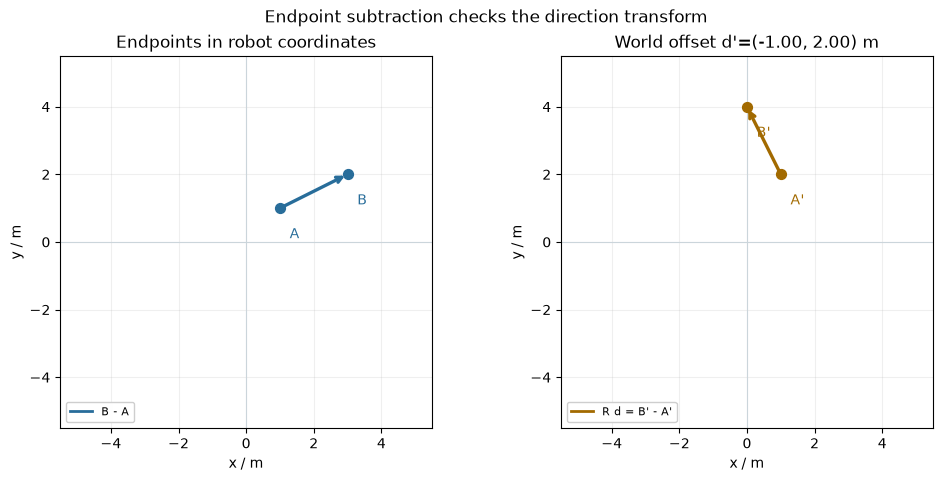

{'direct': array([-1.,  2.]),
 'from_endpoints': array([-1.,  2.]),
 'wrong': array([1., 3.]),
 'error': np.float64(2.23606797749979)}

In [24]:
# Compare the correct offset first. Then enable the deliberate mistake.
# The red arrow shows what happens when a direction accidentally receives a point's weight.
endpoint_experiment()


In [25]:
endpoints_lab = widgets.interactive(
    endpoint_experiment,
    tx=widgets.FloatSlider(value=2, min=-3, max=3, step=0.25,
                           description='Shift x / m', continuous_update=False),
    ty=widgets.FloatSlider(value=1, min=-3, max=3, step=0.25,
                           description='Shift y / m', continuous_update=False),
    heading_degrees=widgets.FloatSlider(value=90, min=-180, max=180, step=15,
                                        description='Turn / deg', continuous_update=False),
    show_wrong=widgets.Checkbox(value=False, description='Treat direction as a point',
                               style={'description_width': 'initial'}),
)

display(endpoints_lab)

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='Shift x / m', max=3.0, min=…

## 4. Rotate around a chosen pivot

**What we know:** P is at $(3,1)$ meters. We want to turn it 90 degrees counterclockwise around a fixed pivot C at $(1,1)$ meters. All these coordinates use the same world axes.

**What we want:** the point's new world position. This is an active movement of P, rather than expressing the same fixed point in another frame.

1. Subtract C because ordinary rotation acts on an offset from its origin. This gives the pivot-to-point displacement $q=p-c=(2,0)$ meters.
2. Rotate that displacement. A quarter-turn gives $q'=Rq=(0,2)$ meters. It still describes an offset from C, rather than a world location.
3. Add C back because we now need the endpoint in world coordinates. The result is $p'=c+q'=(1,3)$ meters.

The three panels show these three quantities separately. The pivot stays fixed, and the point stays on a circle whose radius is its original distance from C.

Combine the steps only after understanding their outputs:
$$
p'=c+R(p-c)=Rp+(c-Rc).
$$
To write the same three steps as a matrix product, we first need a name for a **pure translation**. Here $T(v)$ means "the homogeneous matrix that adds the vector $v$ to a point." It has an identity rotation and puts the translation vector in its last column.

**First, subtract the pivot with $T(-c)$.** For $c=(c_x,c_y)$, the translation vector is $-c=(-c_x,-c_y)$:

$$
T(-c)=
\begin{bmatrix}
1&0&-c_x\\
0&1&-c_y\\
0&0&1
\end{bmatrix},
\qquad
T(-c)\begin{bmatrix}p_x\\p_y\\1\end{bmatrix}
=
\begin{bmatrix}p_x-c_x\\p_y-c_y\\1\end{bmatrix}.
$$

This temporarily shifts the point by minus the pivot's position. Applying the same shift to C puts it at $(0,0)$, which is where an ordinary rotation acts.

**Next, rotate with $R_h$.** This is the rotation $R$ written as a 3×3 matrix with zero translation:

$$
R_h=
\begin{bmatrix}
\cos\theta&-\sin\theta&0\\
\sin\theta&\cos\theta&0\\
0&0&1
\end{bmatrix}.
$$

It turns the shifted point about the temporary origin. Its first two output components are $R(p-c)$.

**Finally, add the pivot back with $T(+c)$.** Its translation vector is $+c=(c_x,c_y)$:

$$
T(+c)=
\begin{bmatrix}
1&0&c_x\\
0&1&c_y\\
0&0&1
\end{bmatrix},
\qquad
T(+c)\begin{bmatrix}q'_x\\q'_y\\1\end{bmatrix}
=
\begin{bmatrix}q'_x+c_x\\q'_y+c_y\\1\end{bmatrix}.
$$

Here $(q'_x,q'_y)$ are the rotated components from the previous step. Adding C restores the point's final world position.

We apply this matrix chain to a **point**, so its homogeneous entry stays $1$ throughout. The intermediate shifted point has the same first two components as the displacement $q$ above; it remains a point in this matrix calculation, so the final translation can act on it.

We can now combine the three defined matrices:

$$
M_c=T(+c)\,R_h\,T(-c)
=
\begin{bmatrix}R&c-Rc\\0\;0&1\end{bmatrix}.
$$

The **right-hand matrix acts first**. Read the product as:

$$
p
\;\xrightarrow{\;T(-c)\;}\;
p-c
\;\xrightarrow{\;R_h\;}\;
R(p-c)
\;\xrightarrow{\;T(+c)\;}\;
c+R(p-c)=p'.
$$

This arrow diagram shows the first two components at each stage; the last entry remains $1$. For C at $(1,1)$ and a 90-degree turn, the sequence is $(3,1)\to(2,0)\to(0,2)\to(1,3)$.

In `rotation_about_pivot` below, these matrices are built by `rigid_transform(-cx, -cy, 0)`, `rigid_transform(0, 0, angle_degrees)`, and `rigid_transform(cx, cy, 0)`, respectively. The return expression places them in multiplication order, with the last step on the left.

Expanded for a pivot $c=(c_x,c_y)$:
$$
M_c=\begin{bmatrix}
\cos\theta&-\sin\theta&c_x-c_x\cos\theta+c_y\sin\theta\\
\sin\theta&\cos\theta&c_y-c_x\sin\theta-c_y\cos\theta\\
0&0&1
\end{bmatrix}.
$$
For C equal to $(1,1)$ and a 90-degree turn:
$$
M_c=\begin{bmatrix}0&-1&2\\1&0&0\\0&0&1\end{bmatrix},
\quad
M_c\begin{bmatrix}3\\1\\1\end{bmatrix}=\begin{bmatrix}1\\3\\1\end{bmatrix},
\quad
M_c\begin{bmatrix}1\\1\\1\end{bmatrix}=\begin{bmatrix}1\\1\\1\end{bmatrix}.
$$

**Explore:** first put the pivot at $(0,0)$. Then change pivot x, then pivot y. Try a negative turn. Finally enable **Compare rotation about world origin** to see what the missing pivot shifts would do.

In [27]:
# We first need an offset from the chosen pivot, so we subtract it.
# We turn that offset and add the pivot back to recover a world position.
def rotation_about_pivot(pivot, angle_degrees):
    cx, cy = np.asarray(pivot, dtype=float)
    return (rigid_transform(cx, cy, 0) @ rigid_transform(0, 0, angle_degrees)
            @ rigid_transform(-cx, -cy, 0))

def pivot_experiment(cx=1.0, cy=1.0, angle_degrees=90.0, show_origin_rotation=False):
    point, pivot = np.array([3.0, 1.0]), np.array([cx, cy])
    relative = point - pivot
    rotated = transform_direction(rigid_transform(0, 0, angle_degrees), relative)
    moved = pivot + rotated
    matrix = rotation_about_pivot(pivot, angle_degrees)
    np.testing.assert_allclose(transform_point(matrix, point), moved, atol=1e-12)
    np.testing.assert_allclose(transform_point(matrix, pivot), pivot, atol=1e-12)
    np.testing.assert_allclose(np.linalg.norm(moved - pivot), np.linalg.norm(relative), atol=1e-12)
    arc = np.array([transform_point(rotation_about_pivot(pivot, angle), point)
                    for angle in np.linspace(0, angle_degrees, 49)])
    wrong = transform_point(rigid_transform(0, 0, angle_degrees), point)
    show_pivot_steps(point, pivot, relative, rotated, moved, arc,
                     wrong if show_origin_rotation else None)
    return {'point': moved, 'pivot': transform_point(matrix, pivot), 'matrix': matrix,
            'radius': np.linalg.norm(relative)}

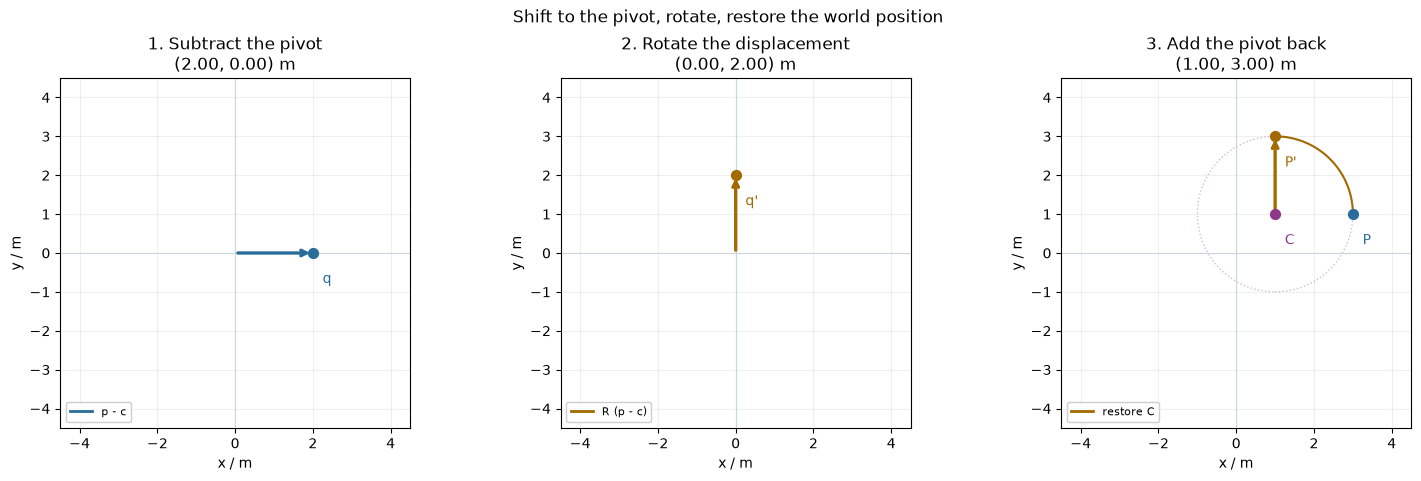

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Pivot x / m', max=3.0, min=…

In [9]:
# Voiceover: Keep the point fixed as the input and choose a different pivot.
# Each preview is calculated from that same starting point, so the slider does not accumulate turns.
pivot_experiment()
pivot_lab = widgets.interactive(
    pivot_experiment,
    cx=widgets.FloatSlider(value=1, min=-2, max=3, step=0.25,
                           description='Pivot x / m', continuous_update=False),
    cy=widgets.FloatSlider(value=1, min=-2, max=3, step=0.25,
                           description='Pivot y / m', continuous_update=False),
    angle_degrees=widgets.FloatSlider(value=90, min=-180, max=180, step=15,
                                      description='Turn / deg', continuous_update=False),
    show_origin_rotation=widgets.Checkbox(value=False, description='Compare rotation about world origin',
                                         style={'description_width': 'initial'}),
)
display(pivot_lab)

## 5. Orbit the robot while keeping its angle to a landmark

### What movement are we trying to create?

In part 4, we moved one point around a fixed pivot. Now that point is the **robot's center**, and the pivot is the **landmark L2**. We also need to decide what happens to the robot's orientation.

We require **both** of the following:

1. **Orbit:** move the robot's center around L2, keeping its distance from L2 constant.
2. **Orientation:** keep the angle between the robot's forward direction and the line **from its center toward L2** constant during that orbit.

The second condition means that if the orbit turns through an angle $\alpha$, the robot's heading must also turn through $\alpha$. If the robot initially faces the landmark, it keeps facing it. If it initially faces at an angle to the landmark, it keeps that angle.

These conditions describe the movement we choose for this experiment. We want to calculate the robot's **new center and new forward direction**, then draw the whole robot at that pose.

### What do we know?

All positions below use world axes. We use different symbols for the robot center and the landmark so that we can distinguish them.

| Quantity | Meaning | Starting example |
| --- | --- | --- |
| $s=(s_x,s_y)$ | Robot center in world meters | $(0,0)$ |
| $\theta$ | Initial robot heading, measured counterclockwise from world +x | $0^\circ$, facing right |
| $c=(c_x,c_y)$ | Fixed landmark position, our orbit's pivot | L2 at $(1,4)$ meters |
| $\alpha$ | Amount of counterclockwise orbit to apply | $90^\circ$ |
| $e=(1,0)$ | Unit forward direction in the robot's own axes | Always $(1,0)$ locally |

$\theta$ and $\alpha$ have different jobs: **Start / deg** chooses the initial heading $\theta$; **Turn / deg** chooses the orbit angle $\alpha$. The local direction $e$ defines the robot's forward axis. We need to find which way that axis points **in the world** after the movement.

### Step 1: Write the robot's current pose matrix

A **pose** is a position together with an orientation. We need a matrix that places the robot's local geometry into the world **before** the orbit:

$$
T_{\text{world}\leftarrow\text{robot}}=
\begin{bmatrix}
\cos\theta&-\sin\theta&s_x\\
\sin\theta&\cos\theta&s_y\\
0&0&1
\end{bmatrix}.
$$

The upper-left rotation describes the robot's current heading. The last column contains its current center in the world. This is `world_from_robot = rigid_transform(*center, robot_heading_degrees)` in the code.

Our starting center is $(0,0)$ and heading is zero, so this particular initial pose is the identity:

$$
T_{\text{world}\leftarrow\text{robot}}=
\begin{bmatrix}1&0&0\\0&1&0\\0&0&1\end{bmatrix}.
$$

It sends the robot's local center $(0,0)$ to world $(0,0)$ and its local forward direction $(1,0)$ to world $(1,0)$. Changing **Start / deg** changes the rotation in this matrix, even though the center remains at the origin.

### Step 2: Write the matrix that performs the orbit

We now need a **movement**, applied to geometry already expressed in world coordinates. From part 4, rotation about the fixed world point $c$ is:

$$
M_c=T(+c)\,R_h(\alpha)\,T(-c).
$$

Here $T(-c)$ shifts by $(-c_x,-c_y)$, $R_h(\alpha)$ turns through the orbit angle, and $T(+c)$ shifts back. These are the three matrices defined in part 4.

For L2 at $(1,4)$ and a 90-degree turn, the rotation sends $c$ to $(-4,1)$. Therefore the combined translation is:

$$
c-R(90^\circ)c=
\begin{bmatrix}1\\4\end{bmatrix}
-
\begin{bmatrix}-4\\1\end{bmatrix}
=
\begin{bmatrix}5\\3\end{bmatrix}.
$$

The complete orbit matrix is:

$$
M_c=
\begin{bmatrix}
0&-1&5\\
1&0&3\\
0&0&1
\end{bmatrix}.
$$

This is `movement = rotation_about_pivot(pivot, angle_degrees)`. Its translation column $(5,3)$ is the net translation produced by the three-step movement; the landmark itself is still at $(1,4)$.

### Step 3: Combine current placement with the movement

For any point on the robot, we need this sequence:

1. Use its **current pose** to obtain its world position.
2. Apply the **orbit movement** to that world position.

Because the right-hand matrix acts first, the new pose is:

$$
T'_{\text{world}\leftarrow\text{robot}}
=
M_c\,T_{\text{world}\leftarrow\text{robot}}.
$$

This is `new_world_from_robot = movement @ world_from_robot`. It combines both operations so that we can send any robot-local point directly to its final world position.

For our starting example, the original pose is the identity, so the result is:

$$
T'_{\text{world}\leftarrow\text{robot}}
=
\begin{bmatrix}
0&-1&5\\
1&0&3\\
0&0&1
\end{bmatrix}.
$$

Its upper-left part is a 90-degree orientation, and its last column is the new robot center. With a different initial heading, the final heading would be $\theta+\alpha$.

### Step 4: Read the new center, forward direction, and body

The robot's center is its **local origin**, and it is a point. Append one so that the movement can change its location:

$$
T'
\begin{bmatrix}0\\0\\1\end{bmatrix}
=
\begin{bmatrix}5\\3\\1\end{bmatrix}.
$$

Therefore the new center is **$(5,3)$ meters**. This is `transform_point(new_world_from_robot, [0, 0])`.

The robot's local forward axis is a **direction**. Append zero so that we obtain its orientation without adding a position:

$$
T'
\begin{bmatrix}1\\0\\0\end{bmatrix}
=
\begin{bmatrix}0\\1\\0\end{bmatrix}.
$$

Therefore the robot now **faces up**, along world +y. The code calculates this in two equivalent stages: `forward` expresses the initial forward axis in the world, then `moved_forward` rotates it using `movement`.

The triangle is the robot's body. Each vertex has fixed robot-local coordinates and is transformed as a **point** by $T'$. For example, its front vertex at local $(0.6,0)$ meters ends up at world $(5,3.6)$ meters. Applying the same pose to every vertex moves and turns the complete shape together.

### Step 5: Check that we satisfied both conditions

**Orbit condition.** Before the movement, the robot-to-landmark distance is $\sqrt{1^2+4^2}=\sqrt{17}$ meters. Afterwards the vector from the robot center to L2 is:

$$
c-s'=(1,4)-(5,3)=(-4,1).
$$

Its length is also $\sqrt{17}$ meters. The center stayed on the required circle.

**Orientation condition.** The forward vector changed from $(1,0)$ to $(0,1)$. The vector toward L2 changed from $(1,4)$ to $(-4,1)$. **Both vectors turned by 90 degrees**, so the angle between them stayed the same.

More generally, the new center is $s'=c+R(\alpha)(s-c)$. Thus:

$$
f'=R(\alpha)f,
\qquad
c-s'=R(\alpha)(c-s),
$$

where $f$ is the original forward direction in the world. The same rotation acts on the two vectors whose angle we want to preserve.

We also check this using the inverse poses from episode 002. Each inverse converts the fixed landmark's world position into robot coordinates, before or after the movement. In this example, both calculations give local $(1,4)$ meters: the landmark remains **one meter forward and four meters to the robot's left**. This confirms the chosen relative angle and distance.

The code checks those unchanged local coordinates, the orbit radius, the unit forward length, and the distance between two body vertices.

### Read the diagram and explore

The blue triangle is the original robot; the gold triangle is its new pose. Their center dots mark positions, and their arrows show forward directions. The purple C is the fixed pivot. Compare each forward arrow with the dotted line joining its center to C: **that relative angle should agree before and after**. The circle and gold arc show the center's orbit.

1. Choose **L2**, set **Start / deg** to zero, and set **Turn / deg** to zero. Then turn to **90 degrees**. Look for center $(5,3)$, forward $(0,1)$, and the unchanged angle toward L2.
2. Keep the same starting heading and try other positive or negative orbit angles. The center follows the circle and the forward arrow turns by the same amount.
3. Keep L2 and the 90-degree orbit, then set **Start / deg** to **30 degrees**. The center still ends at $(5,3)$, but the final heading is now $120^\circ$. Changing the starting heading selects a different initial angle toward the landmark; that new angle is preserved during its orbit.
4. Finally choose **Robot center** as pivot. This is the special case of turning in place: the center stays fixed while the heading changes. There is no nonzero center-to-pivot line in this case, so the relative-angle condition is undefined. **World origin** gives the same result here because the robot starts at $(0,0)$.

Each preview starts from the chosen initial pose; changing a slider does not accumulate movements. The playground's separate **Apply orbit** action places the robot at a selected preview pose.


In [28]:
# We orbit the robot around the landmark while keeping its angle toward that landmark constant.
# We combine its current pose with the orbit movement, then read its new center and forward direction.
def robot_rotation_experiment(pivot_name='L2', angle_degrees=90.0, robot_heading_degrees=0.0):
    center = np.array([0.0, 0.0])
    pivots = {'robot': center, 'world': np.zeros(2), 'L2': np.array([1.0, 4.0])}
    pivot = pivots[pivot_name]
    # T places robot-local geometry into the world at its initial pose.
    world_from_robot = rigid_transform(*center, robot_heading_degrees)
    # M acts on world geometry: shift by minus the pivot, turn, then shift back.
    movement = rotation_about_pivot(pivot, angle_degrees)
    # M @ T first places the robot in the world, then applies the orbit movement.
    new_world_from_robot = movement @ world_from_robot
    # The local center is a point, so its homogeneous entry is one.
    moved_center = transform_point(new_world_from_robot, [0, 0])
    # The local forward axis has weight zero. Only rotations affect its world direction.
    forward = transform_direction(world_from_robot, [1, 0])
    moved_forward = transform_direction(movement, forward)
    local_shape = np.array([[0.6, 0], [-0.3, 0.35], [-0.3, -0.35]])
    before_shape = np.array([transform_point(world_from_robot, vertex) for vertex in local_shape])
    after_shape = np.array([transform_point(new_world_from_robot, vertex) for vertex in local_shape])
    radius = np.linalg.norm(center - pivot)
    np.testing.assert_allclose(np.linalg.norm(moved_center - pivot), radius, atol=1e-12)
    # Inverse poses describe the landmark from the robot before and after the orbit.
    # Unchanged local coordinates verify its distance and bearing relative to the robot.
    pivot_in_robot_before = transform_point(np.linalg.inv(world_from_robot), pivot)
    pivot_in_robot_after = transform_point(np.linalg.inv(new_world_from_robot), pivot)
    np.testing.assert_allclose(pivot_in_robot_after, pivot_in_robot_before, atol=1e-12)
    np.testing.assert_allclose(np.linalg.norm(moved_forward), 1, atol=1e-12)
    np.testing.assert_allclose(np.linalg.norm(after_shape[1] - after_shape[0]),
                               np.linalg.norm(before_shape[1] - before_shape[0]), atol=1e-12)
    arc = np.array([transform_point(rotation_about_pivot(pivot, angle), center)
                    for angle in np.linspace(0, angle_degrees, 49)])
    show_robot_rotation(before_shape, after_shape, center, moved_center,
                         forward, moved_forward, pivot, arc, radius)
    return {'center': moved_center, 'forward': moved_forward, 'radius': radius,
            'pivot': pivot.copy(), 'pose': new_world_from_robot}

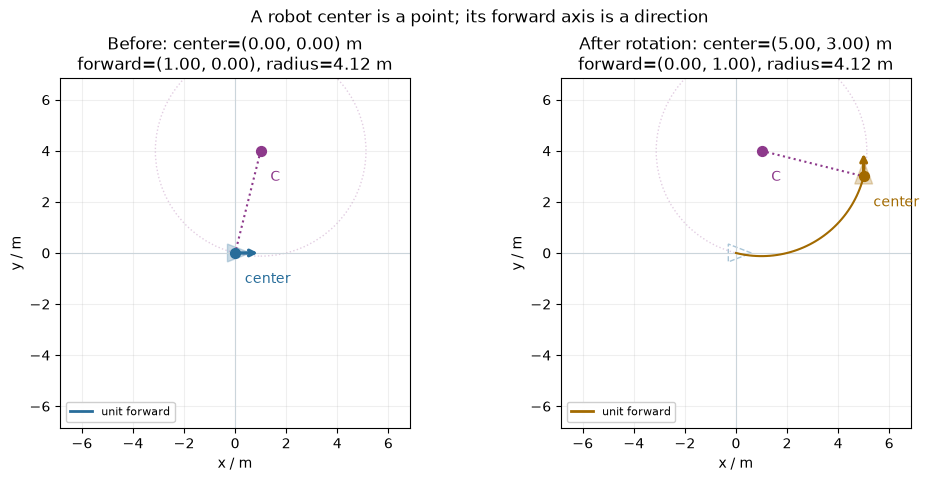

interactive(children=(Dropdown(description='Pivot', index=2, options=(('Robot center', 'robot'), ('World origi…

In [11]:
# Voiceover: Choose L2 and turn through a quarter-circle. Compare each forward arrow with its line toward L2.
# Then change the starting heading, and compare with turning in place about the robot center.
robot_rotation_experiment()
robot_lab = widgets.interactive(
    robot_rotation_experiment,
    pivot_name=widgets.Dropdown(options=[('Robot center', 'robot'), ('World origin', 'world'), ('L2 at (1, 4) m', 'L2')],
                                value='L2', description='Pivot'),
    angle_degrees=widgets.FloatSlider(value=90, min=-180, max=180, step=15,
                                      description='Turn / deg', continuous_update=False),
    robot_heading_degrees=widgets.FloatSlider(value=0, min=-180, max=180, step=15,
                                              description='Start / deg', continuous_update=False),
)
display(robot_lab)

## 6. An editable check and the playground bridge

Change the pivot and signed angle below. Predict the point and direction before running the cell. We reverse the same pivot rotation to recover the starting point, using the inverse already learned in episode 002.

For the initial values, a negative quarter-turn around L2 moves the center from $(0,0)$ to $(-3,5)$ meters. Its forward vector becomes $(0,-1)$, and its radius remains $\sqrt{17}$ meters.

The notebook used NumPy. In the playground, `transformDirection` uses the same homogeneous weight zero with ml-matrix. `rotationAboutPivot` reuses the existing composition utility for the shift, turn, and shift-back product.

Open the [robot-world project](../../projects/robot-world/README.md), pause, and reset. Select L2 as the pivot and set 90 degrees. The center preview should show $(5,3)$ meters and the forward preview $(0,1)$. The purple pivot stays fixed. The gold ring and arc show the proposed rotation. Apply it to change the paused robot's pose, then inspect the existing landmark table. Camera and frame-axis controls remain presentation choices.

**Takeaway:** points carry locations, directions carry offsets, and a pivot determines where a rotation is centered. A correct rigid transform preserves vector lengths and distances while applying the right translation to each kind of quantity.

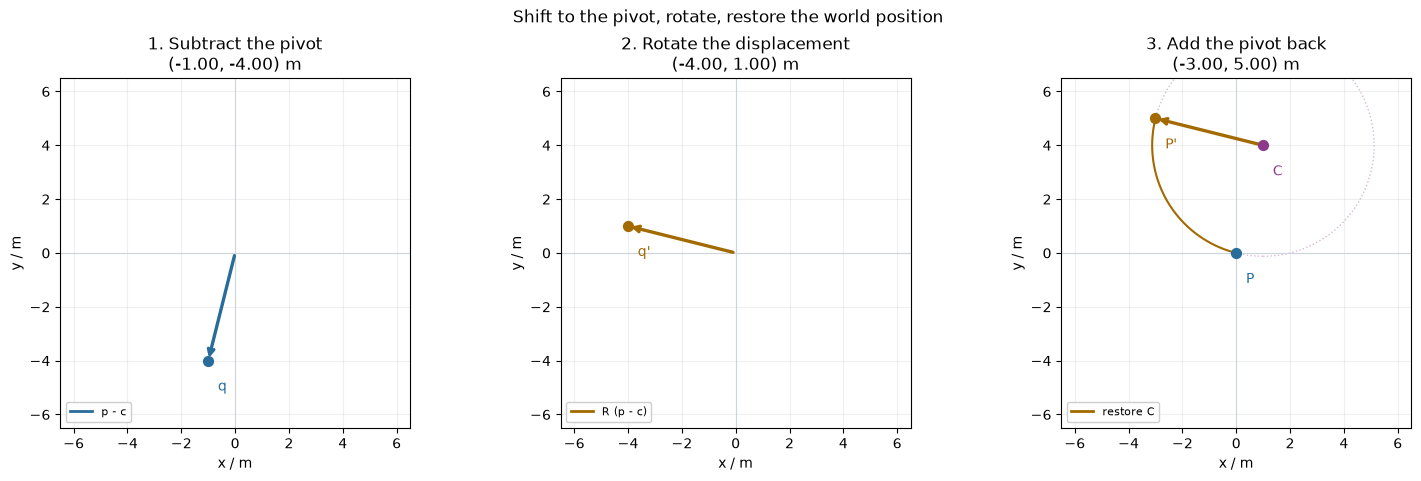

Center / m: [-3.  5.] Unit forward: [ 0. -1.]
Recovered center / m: [0. 0.]


In [12]:
# Voiceover: Use what we learned to predict a signed rotation, then reverse it.
# The recovered point, unchanged radius, and unit forward vector check three different parts of the result.
challenge_pivot = np.array([1.0, 4.0])
challenge_angle_degrees = -90.0
challenge_center = np.array([0.0, 0.0])
challenge_forward = np.array([1.0, 0.0])
movement = rotation_about_pivot(challenge_pivot, challenge_angle_degrees)
moved_center = transform_point(movement, challenge_center)
moved_forward = transform_direction(movement, challenge_forward)
recovered_center = transform_point(np.linalg.inv(movement), moved_center)
np.testing.assert_allclose(recovered_center, challenge_center, atol=1e-12)
np.testing.assert_allclose(np.linalg.norm(moved_center - challenge_pivot),
                           np.linalg.norm(challenge_center - challenge_pivot), atol=1e-12)
np.testing.assert_allclose(np.linalg.norm(moved_forward), 1, atol=1e-12)
show_pivot_steps(challenge_center, challenge_pivot, challenge_center - challenge_pivot,
                 moved_center - challenge_pivot, moved_center,
                 np.array([transform_point(rotation_about_pivot(challenge_pivot, a), challenge_center)
                           for a in np.linspace(0, challenge_angle_degrees, 49)]), None)
print('Center / m:', moved_center, 'Unit forward:', moved_forward)
print('Recovered center / m:', recovered_center)